# **Aula 6 - Imputação e Normalização de Dados**<font size=3>

## **Intodução**<font size=3>

Diferentes problemas, na maioria dos casos, não podem ser resolvidos com a mesma solução, e diante disso, existe algumas práticas que podem ser feitas para solucionar alguns deles quando estamos trababalhando com uma base de dados.

A imputação estima valores que não foram observados através de uma estimativa, escalonamento muda a escala numérica de variáveis a fim de as deixar sobre um mesmo patamar comparável, e as transformações não lineares alteram as distâncias entre as observações de modo que consiga reduzir a assimetria.

## **1. Preparando a base**<font size=3>

In [ ]:
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

from sklearn.preprocessing import MinMaxScaler, PowerTransformer, RobustScaler, StandardScaler

sns.set_theme(style="whitegrid", palette="colorblind")

Iniciou-se a aula com a importação das bibliotecas necessárias para o carregamento, transformação e visualização dos dados.

In [ ]:
column_names = {
    "parking spaces": "parking_spaces",
    "hoa (R$)": "hoa",
    "rent amount (R$)": "rent_amount",
    "property tax (R$)": "property_tax",
    "total (R$)": "total",
}

In [ ]:
imoveis = (
    pd.read_csv("/content/drive/MyDrive/UFRN/Datasets/imoveis_sao_paulo.csv")
    .rename(columns=column_names)
    .drop_duplicates()
    .reset_index(drop=True)
    .assign(
        property_type=lambda df: np.where(
            df["floor"].isna(),
            "casa",
            "apartamento",
        )
    )
)

Para facilitar as tarefas que serão realizadas com a base, os nomes das colunas foram alterados para uma simples padronização. E após isso, as linhas duplicadas foram removidas e "property_type" foi criada para definir os imóveis sem andar como casas.

### **1.1. Os três problemas da aula**<font size=3>

In [ ]:
missing = (
    imoveis[["hoa", "parking_spaces", "floor"]]
    .isna()
    .mean()
    .mul(100)
)

scales = (
    imoveis[["rooms", "area", "rent_amount"]]
    .median()
)

limit = imoveis["rent_amount"].quantile(.99)

Três objetos foram criados para montar o gráfico no próximo bloco de código e identificar alguns problemas da base. A porcentagem de valores ausentes nas colunas "hoa", "parking_spaces" e "floor" é definida com "missing" para identificar alguma coluna que destoa das demais, "scales" calcula a mediana de "rooms", "area" e "rent_amount" para ver se as variáveis numéricas estão na mesma grandeza, e "limit" retorna o percentil 99 do aluguel para recortar o 1% mais extremo na base de dados.

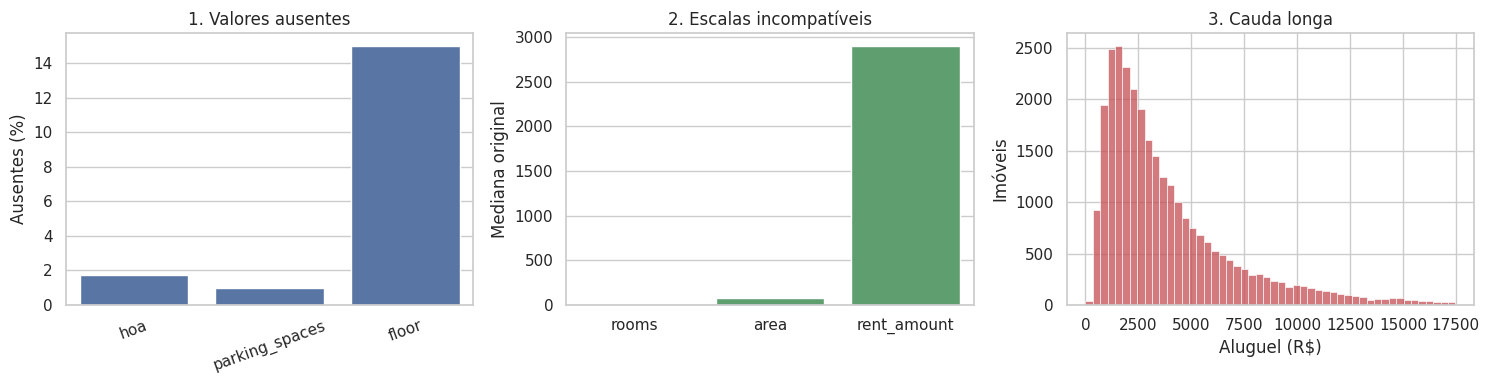

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))

sns.barplot(
    x=missing.index,
    y=missing.values,
    ax=axes[0],
    color="#4C72B0",
)
axes[0].set(
    title="1. Valores ausentes",
    ylabel="Ausentes (%)",
    xlabel="",
)
axes[0].tick_params(axis="x", rotation=20)

sns.barplot(
    x=scales.index,
    y=scales.values,
    ax=axes[1],
    color="#55A868",
)
axes[1].set(
    title="2. Escalas incompatíveis",
    ylabel="Mediana original",
    xlabel="",
)

sns.histplot(
    imoveis["rent_amount"],
    bins=50,
    binrange=(0, limit),
    ax=axes[2],
    color="#C44E52",
)
axes[2].set(
    title="3. Cauda longa",
    xlabel="Aluguel (R$)",
    ylabel="Imóveis",
)

plt.tight_layout()
plt.show()

O primeiro gráfico mostra que a coluna "floor", em comparação com as demais, possui uma quantidade maior do que o normal de valores ausentes com 15% do total, indicando que possa existir uma possível causa para isso, tornando-se necessário uma investigação. Com o segundo gráfico, conclue-se que a escala de grandeza em que aluguel encontra-se está muito acima das demais, mostrando uma grande incompatibilidade com "rooms" e "area". Ao final, o terceiro gráfico mostra como o aluguel está distribuído, e confirma uma cauda muito alongada a direita, em que os valores dos aluguéis concentram-se em valores abaixo do limar de R$ 7.500.

## **2. Ausência estrutural**<font size=3>

In [ ]:
(
    imoveis
    .groupby("property_type")
    .agg(
        imoveis=("property_type", "size"),
        proporcao_sem_andar=(
            "floor",
            lambda x: (
                x
                .isna()
                .mean()
            ),
        ),
    )
)

,imoveis,proporcao_sem_andar
property_type,,
apartamento,25024,0.0
casa,4415,1.0


Ausência estrutural é uma lacuna entre informações que não representa uma falha entre os dados, portanto, ao observar a tabela criada acima, a razão para que a coluna "floor" possua os valores ausentes, como foi observado anteriormente, é a inclusão de um total de 4415 casas entre os imóveis da base de dados. Vale lembrar que também existem casos em que a ausência pode representar uma informação perdida, sendo necessário analisar os casos encontrados e definir uma solução, como a imputação.

## **3. Imputação: o impacto das alternativas**<font size=3>

A imputação substitui um valor ausente por uma estimativa calculada a partir das informações disponíveis, como uma medida ou métodos multivariados, os quais estimam o valor a partir de outras variáveis.

In [ ]:
rng = np.random.default_rng(42)

def erase_at_random(values, share):
    return values.mask(rng.random(len(values)) < share)

imoveis_true = (
    imoveis
    .dropna(subset=["hoa", "parking_spaces"])
    .reset_index(drop=True)
)

Uma fração dos valores e a base completa, a qual servirá como gabarito, são apagadas para realizar um apagamento simulado.

In [ ]:
imoveis_missing = (
    imoveis_true
    .assign(
        rooms=lambda df: erase_at_random(df["rooms"], .10),
        rent_amount=lambda df: erase_at_random(df["rent_amount"], .15),
        furniture=lambda df: erase_at_random(df["furniture"], .08),
    )
)

Lacunas nas colunas com variáveis de tipos diferentes foram criadas, as quais são "rooms", "rent_amount" e "furniture". E a respeito das proporções, foram incluídas 10%, 15% e 8%.

In [ ]:
(
    imoveis_missing[["rooms", "rent_amount", "furniture"]]
    .isna()
    .sum()
    .to_frame("ausentes")
    .assign(
        proporcao=lambda x: (
            x.ausentes / len(imoveis_missing)
        ).round(3)
    )
)

,ausentes,proporcao
rooms,2783,0.097
rent_amount,4308,0.150
furniture,2254,0.079


De acordo com a saída acima, "rooms" teve 2783 colunas ausentes, "furniture" ficou com 2254 e "rent_amount" atingiu 4308, respeitando as proporções definidas anteriormente.

### **3.1. Média, mediana e mediana agrupada**<font size=3>

In [ ]:
rent_mean = (
    imoveis_missing.rent_amount
    .mean()
)

rent_median = (
    imoveis_missing.rent_amount
    .median()
)

Cria-se constantes que podem servir para a imputação pela média ou mediana.

In [ ]:
rent_group = (
    imoveis_missing
    .groupby("tier")
    .rent_amount
    .transform(lambda x: x.fillna(x.median()))
    .fillna(rent_median)
)

Também é possível realizar a imputação usando um método de mediana por tier, o qual calcula a mediana para imputação apenas entre as observações do mesmo grupo.

In [ ]:
rent_versions = {
    "Original": imoveis_true.rent_amount,
    "Com lacunas": imoveis_missing.rent_amount,
    "Média": imoveis_missing.rent_amount.fillna(rent_mean),
    "Mediana": imoveis_missing.rent_amount.fillna(rent_median),
    "Mediana por tier": rent_group,
}

As diferentes versões foram agrupadas para comparação.

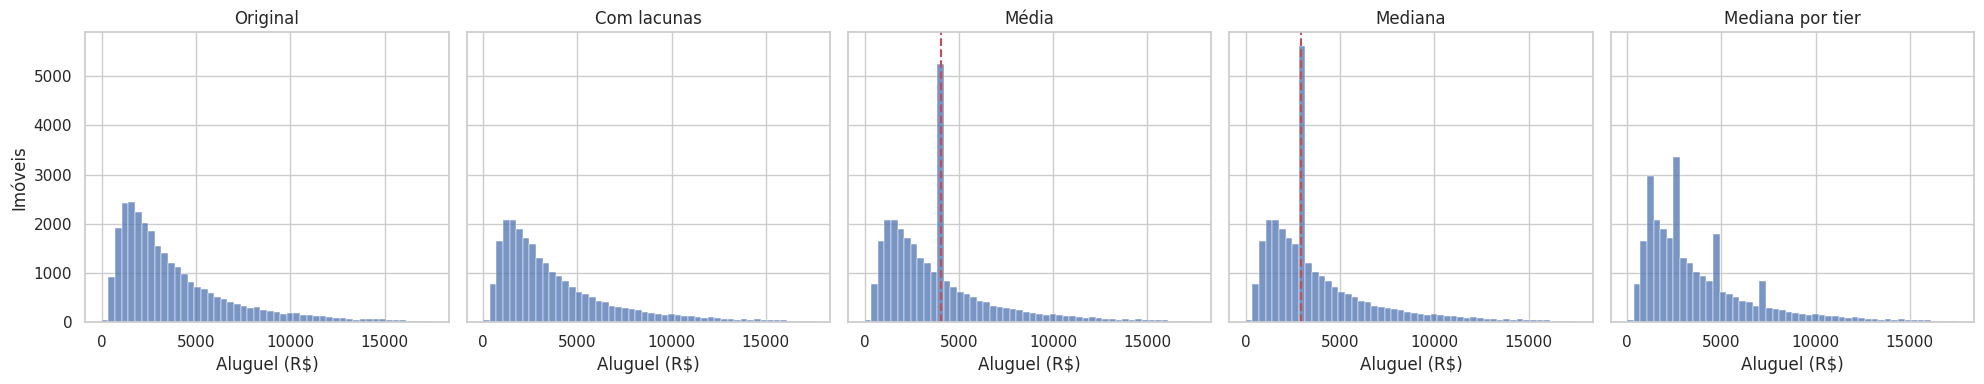

In [ ]:
fig, axes = plt.subplots(1, 5, figsize=(20, 4), sharey=True)

limit = imoveis_true.rent_amount.quantile(.99)

for ax, (label, values) in zip(axes, rent_versions.items()):
    sns.histplot(
        values.dropna(),
        bins=50,
        binrange=(0, limit),
        ax=ax,
        color="#4C72B0",
    )
    ax.set(
        title=label,
        xlabel="Aluguel (R$)",
        ylabel="Imóveis",
    )
    if label == "Média":
        ax.axvline(
            rent_mean,
            color="#C44E52",
            linestyle="--",
        )
    if label == "Mediana":
        ax.axvline(
            rent_median,
            color="#C44E52",
            linestyle="--",
        )

plt.tight_layout()
plt.show()

A base original e com lacunas acabam por serem muito semelhantes, contudo, quando observamos a média e mediana, vemos que um pico artificial é criado, a dispersão é reduzida e ambas escolhem uma constante semelhante para preencher as lacunas, e o método de mediana por tier realiza uma melhor preservação do histograma ao conseguir distribuir as lacunas entre vários grupos diferentes.

#### **3.1.1. Erro absoluto médio (MAE)**<font size=3>

O erro da imputação é calculada com a métrica MAE que é a média das diferenças obtidas entre o valor verdadeiro e o valor imputado.

In [ ]:
rent_missing = imoveis_missing.rent_amount.isna()

truth = imoveis_true.loc[rent_missing, "rent_amount"]

Os valores verdadeiros das posições apagadas são recuperados do gabarito.

In [ ]:
(
    pd.Series(
        {
            "Média": (
                (truth - rent_mean)
                .abs()
                .mean()
            ),
            "Mediana": (
                (truth - rent_median)
                .abs()
                .mean()
            ),
            "Mediana por tier": (
                (truth - rent_group[rent_missing])
                .abs()
                .mean()
            ),
        },
        name="MAE (R$)",
    )
    .round(2)
    .to_frame()
)

,MAE (R$)
Média,2505.30
Mediana,2313.52
Mediana por tier,1820.84


Um menor valor de MAE indica superioridade, e conforme observado na tabela acima, a mediana consegue se sair melhor do que a média ao reduzir o erro médio, contudo, é possível concluir que a mediana por tier conseguiu obter o melhor resultado, tendo em vista que usa a informação adicional do padrão do imóvel.

### **3.2. Moda e variáveis discretas**<font size=3>

Para variáveis categóricas nominais, é possível usar apenas a moda, ou seja, a categoria que ocorre com maior frequência.

In [ ]:
furniture_mode = (
    imoveis_missing.furniture
    .mode()
    .iloc[0]
)

furniture_mode

'not furnished'

Calculando a moda de "furniture", definimos que a categoria mais frequenta é "not furnished".

In [ ]:
(
    pd.concat(
        {
            "Antes": imoveis_missing.furniture.value_counts(dropna=False),
            "Depois da moda": (
                imoveis_missing.furniture
                .fillna(furniture_mode)
                .value_counts()
            ),
        },
        axis=1,
    )
    .fillna(0)
)

,Antes,Depois da moda
furniture,,
not furnished,17265,19519.0
furnished,9122,9122.0
NaN,2254,0.0


Na tabela acima, vemos o efeito de aplicar a imputação com a moda, uma vez que a frequência da categoria "not_furnished" aumentou artificialmente de 17265 para 19519, sendo necessário considerar o efeito disso sobre a distribuição.

In [ ]:
(
    pd.Series(
        {
            "média": imoveis_missing.rooms.mean(),
            "mediana": imoveis_missing.rooms.median(),
            "moda": (
                imoveis_missing.rooms
                .mode()
                .iloc[0]
            ),
        },
        name="quartos",
    )
    .to_frame()
)

,quartos
média,2.262085
mediana,2.000000
moda,2.000000


Além disso, a respeito das variáveis discretas, é necessário ter atenção com a utilização da média que pode ser incompatível dependendo da variável que estamos tratando, como no uso acima em que observamos que a média do quarto é 2.26, sendo impossível imputar o total de quartos de uma amostra com esse valor.

### **3.3 Resumo da imputação**<font size=3>

Diante das diferentes situações em que a imputação pode ser utilizada, temos o uso da média para as variáveis contínuas ou distribuição simétrica, mediana para distribuição assimétrica ou com a presença de extremos, estatistica baseada por grupo quando há uma variação entre agrupamentos conhecidos, e por fim, a moda e mediana podem ser usadas para variáveis categóricas ou discretas.

## **4. Escalonamento: a régua muda, a forma não**<font size=3>

In [ ]:
n_epochs = 35
tamanho_batch = 16

Epoch 1/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 12s 442ms/step - acc: 0.5306 - loss: 0.7325 - val_acc: 0.5400 - val_loss: 0.6892
Epoch 2/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 46ms/step - acc: 0.5000 - loss: 0.6956 - val_acc: 0.4600 - val_loss: 0.6931
Epoch 3/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 48ms/step - acc: 0.4949 - loss: 0.6933 - val_acc: 0.6400 - val_loss: 0.6926
Epoch 4/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 42ms/step - acc: 0.5102 - loss: 0.6928 - val_acc: 0.6400 - val_loss: 0.6900
Epoch 5/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 40ms/step - acc: 0.5612 - loss: 0.6889 - val_acc: 0.6800 - val_loss: 0.6755
Epoch 6/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - acc: 0.6224 - loss: 0.6658 - val_acc: 0.7200 - val_loss: 0.6278
Epoch 7/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - acc: 0.6429 - loss: 0.6337 - val_acc: 0.7000 - val_loss: 0.5791
Epoch 8/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - acc: 0.7041 - loss: 0.5718 - val_acc: 0.7600 - val_loss: 0.4771
Epoch 9/50
13/13 ━━━━━━━━━━━━━━━━━━━━ 1s 38ms/step - acc: 0.78

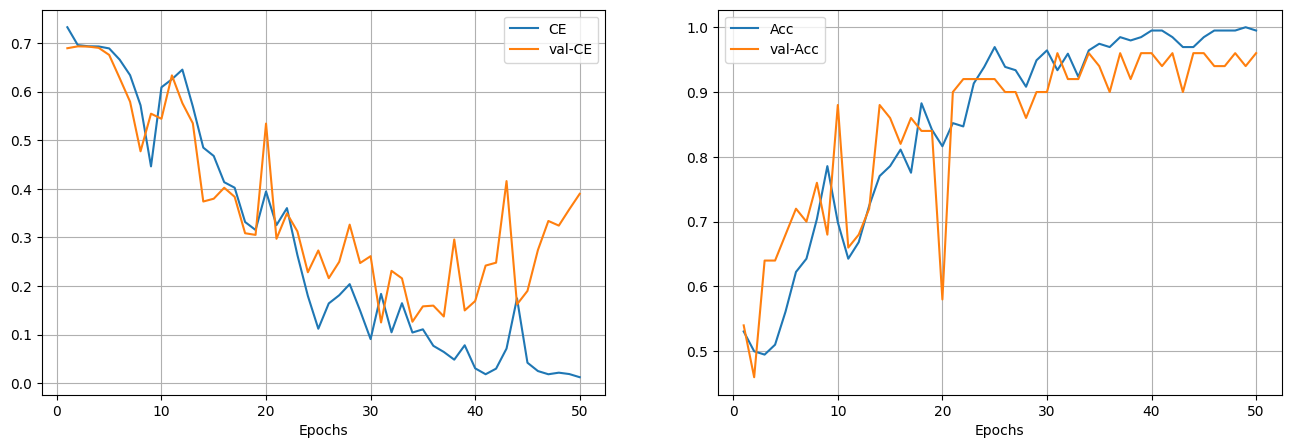

In [ ]:
final_training = False

if not final_training:
    report = model.fit(x=x_train, y=y_train, validation_split=0.2,
                       epochs=n_epochs, batch_size=tamanho_batch)

    loss = report.history['loss']
    acc = report.history['acc']

    val_loss = report.history['val_loss']
    val_acc = report.history['val_acc']

    epochs = np.linspace(1, len(loss), len(loss))

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))

    ax[0].plot(epochs, loss, label='CE')
    ax[0].plot(epochs, val_loss, label='val-CE')

    ax[1].plot(epochs, acc, label='Acc')
    ax[1].plot(epochs, val_acc, label='val-Acc')

    for i in range(2):
        ax[i].set_xlabel("Epochs")
        ax[i].legend()
        ax[i].grid()

    plt.show()

### **5. Treinamento final:**<font size=3>

Epoch 1/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 12s 346ms/step - acc: 0.5000 - loss: 0.8067
Epoch 2/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 36ms/step - acc: 0.4756 - loss: 0.6946
Epoch 3/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - acc: 0.5325 - loss: 0.6958
Epoch 4/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - acc: 0.5163 - loss: 0.6948
Epoch 5/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - acc: 0.5203 - loss: 0.6879
Epoch 6/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - acc: 0.6382 - loss: 0.6416
Epoch 7/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 32ms/step - acc: 0.6951 - loss: 0.6636
Epoch 8/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - acc: 0.7114 - loss: 0.5127
Epoch 9/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 33ms/step - acc: 0.8943 - loss: 0.3206
Epoch 10/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - acc: 0.8577 - loss: 0.3581
Epoch 11/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - acc: 0.9228 - loss: 0.3598
Epoch 12/35
16/16 ━━━━━━━━━━━━━━━━━━━━ 1s 35ms/step - acc: 0.9390 - loss: 0.2177
Epoch 13/35
16/16 ━━━━━━━━━━━━━━━━━

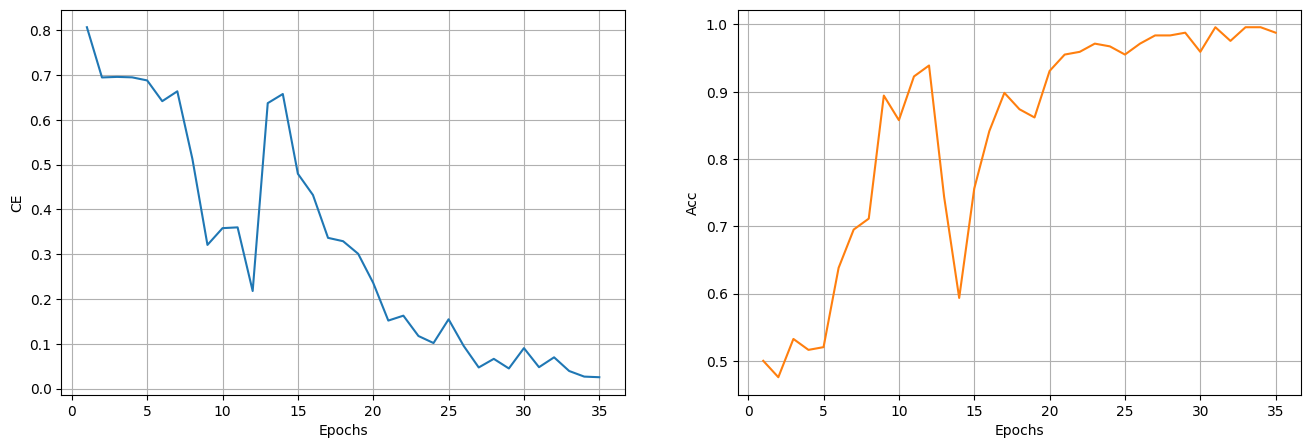

In [ ]:
final_training = True

if final_training:
    report_final = model.fit(x=x_train, y=y_train, epochs=n_epochs, batch_size=tamanho_batch)

    loss = report_final.history['loss']
    acc = report_final.history['acc']

    epochs = np.linspace(1, len(loss), len(loss))

    fig, ax = plt.subplots(1, 2, figsize=(16, 5))

    ax[0].plot(epochs, loss, c='tab:blue')
    ax[1].plot(epochs, acc, c='tab:orange')

    ax[0].set_ylabel('CE')
    ax[1].set_ylabel('Acc')

    for i in range(2):
        ax[i].set_xlabel("Epochs")
        ax[i].grid()

    plt.show()

### **6. Avaliação do modelo:**<font size=3>

In [ ]:
if final_training:
    ce, acc = model.evaluate(x=x_test, y=y_test, batch_size=tamanho_batch)

    print(f"\nCE = {ce:.4f}, acc = {acc:.4f}\n")

5/5 ━━━━━━━━━━━━━━━━━━━━ 2s 191ms/step - acc: 0.9846 - loss: 0.1475

CE = 0.1475, acc = 0.9846



In [ ]:
if final_training:

    y_pred_prob = model.predict(x_test)
    y_pred = (y_pred_prob >= 0.5).astype(int)

    print("\ny-pred | y-test")
    print("---------------")

    for p, y in zip(y_pred[:10], y_test[:10]):
      print(f" {p}  |  {y}")

3/3 ━━━━━━━━━━━━━━━━━━━━ 1s 262ms/step

y-pred | y-test
---------------
 [1]  |  1
 [0]  |  0
 [0]  |  0
 [1]  |  1
 [0]  |  0
 [0]  |  0
 [0]  |  0
 [1]  |  1
 [1]  |  1
 [0]  |  0


In [ ]:
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay

print(classification_report(y_test, y_pred, target_names=labels))

              precision    recall  f1-score   support

         ESP       0.97      1.00      0.99        35
     ARDUINO       1.00      0.97      0.98        30

    accuracy                           0.98        65
   macro avg       0.99      0.98      0.98        65
weighted avg       0.99      0.98      0.98        65



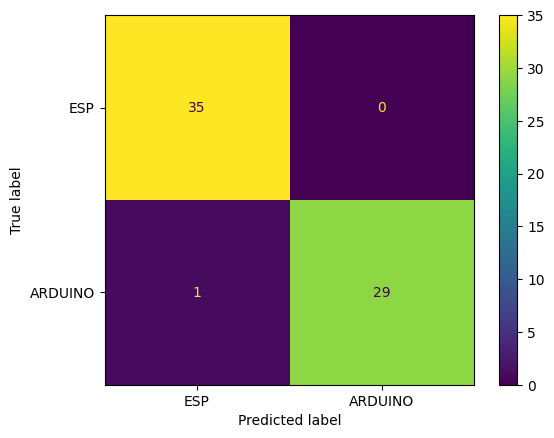

In [ ]:
cm = confusion_matrix(y_test, y_pred)

disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=labels)
disp.plot()
plt.show()